# 03 — Evaluación de los estimadores de pitch sobre la base completa PTDB-TUG

**TPI Señales y Sistemas 2026 — Grupo 3: Codificación de la voz**

En el notebook 02 se compararon los tres estimadores de F0 y decisión sonoro/sordo para LPC10 (capítulo, cepstrum y YIN)
sobre 200 grabaciones. Acá se repite la evaluación sobre **toda la base**: 20 hablantes (10 mujeres, 10 hombres) y
4718 grabaciones, para ver si los resultados se sostienen con más datos y cuánto varían de un hablante a otro.

- **Mismos métodos, parámetros y umbrales** que en el notebook 02 (no se recalibra nada).
- Se **excluyen las 40 grabaciones usadas para calibrar** los umbrales, para que la evaluación sea con datos que no
  intervinieron en ninguna elección.
- Métricas: **VDE** (decisión sonoro/sordo), **GPE** (error grueso, > 20 %) y **FPE** (error fino), por sexo.
- Como se acordó con el tutor, **no se corrigen valores atípicos**: se mide cada estimador tal como funcionaría dentro
  del codificador.

Contenido: la base de datos · 0. acceso a los datos · 1. funciones · 2. procesamiento de la base · 3. resultados por sexo · 4. resultados por hablante ·
5. error vs F0 del hablante · 6. errores de octava · 7. escuchar cualquier grabación · 8. conclusiones.

## La base de datos: PTDB-TUG

### Qué es

**PTDB-TUG** (*Pitch Tracking Database from Graz University of Technology*) es una base de voz creada por el Laboratorio de
Procesamiento de Señales y Comunicación del Habla (SPSC) de la Universidad Tecnológica de Graz (Austria) para evaluar
algoritmos de **estimación de pitch**. Las grabaciones se hicieron entre diciembre de 2009 y enero de 2010 y la base se
publicó en 2011 (Pirker et al., Interspeech 2011). Es de acceso libre bajo licencia *Open Database License* (ODbL 1.0).

Lo que la hace útil para este trabajo es que cada frase se grabó **al mismo tiempo con un micrófono y con un
laringógrafo**, y la base trae una **F0 de referencia** calculada sobre el laringógrafo. Eso permite medir el error de
cualquier estimador de pitch que trabaje sobre la señal del micrófono, que es lo que recibiría un codificador LPC10.

### Hablantes

20 hablantes nativos de inglés: **10 mujeres (F01–F10) y 10 hombres (M01–M10)**, de 22 a 48 años, de cinco países. El
reporte de la base no informa sobre su salud vocal. Se agrupan en **10 pares**: la mujer *k* y el hombre *k* leyeron exactamente las mismas
frases. La F0 se calculó sobre la referencia de todas sus grabaciones (media y rango del 5 % al 95 % de las tramas sonoras).

| Par | Mujer | Edad | País | F0 media [Hz] (p5–p95) | Hombre | Edad | País | F0 media [Hz] (p5–p95) |
|---|---|---|---|---|---|---|---|---|
| 1 | F01 | 40 | Irlanda | 194 (150–257) | M01 | 24 | Sudáfrica | 118 (92–158) |
| 2 | F02 | 25 | EE. UU. | 218 (166–291) | M02 | 40 | Inglaterra | 96 (73–128) |
| 3 | F03 | 22 | Canadá | 194 (170–230) | M03 | 35 | Inglaterra | 86 (65–113) |
| 4 | F04 | 26 | Canadá | 181 (101–248) | M04 | 26 | EE. UU. | 110 (92–136) |
| 5 | F05 | 48 | EE. UU. | 190 (148–242) | M05 | 25 | Inglaterra | 133 (93–192) |
| 6 | F06 | 28 | EE. UU. | 182 (88–232) | M06 | 23 | EE. UU. | 117 (94–152) |
| 7 | F07 | 24 | EE. UU. | 192 (170–224) | M07 | 24 | EE. UU. | 139 (100–180) |
| 8 | F08 | 22 | Inglaterra | 187 (100–269) | M08 | 24 | Inglaterra | 95 (81–118) |
| 9 | F09 | 22 | EE. UU. | 215 (170–272) | M09 | 24 | Canadá | 112 (89–155) |
| 10 | F10 | 35 | EE. UU. | 157 (80–198) | M10 | 33 | EE. UU. | 106 (75–144) |

En conjunto, la F0 media es de **191 Hz en mujeres** (p5–p95: 100–252 Hz) y **111 Hz en hombres** (77–159 Hz). Los rangos
se superponen poco, por eso tiene sentido separar los resultados por sexo.

### Qué se leyó

El texto son **2342 frases fonéticamente ricas del corpus TIMIT**, de tres tipos:

| Tipo | Cantidad | Quién las lee | Por hablante | Ejemplo |
|---|---|---|---|---|
| `sa` (dialectales) | 2 | los 20 hablantes | 2 | *sa1: "She had your dark suit in greasy wash water all year."* · *sa2: "Don't ask me to carry an oily rag like that."* |
| `sx` (fonéticamente compactas) | 450 | una mujer y un hombre (el par) | 45 | *sx409: "Eating spinach nightly increases strength miraculously."* |
| `si` (fonéticamente diversas) | 1890 | una mujer y un hombre (el par) | 189 | *si1291: "They should live in modest circumstances, avoiding all conspicuous consumption."* |

Cada hablante leyó **236 frases**, en total **4720 grabaciones**. Por un error durante la grabación faltan 2 (`si1912` y
`si1913` de F08), así que hay **4718 disponibles**. Es habla **leída** de una pantalla, no espontánea.

### Cómo se grabó

- **Lugar:** estudio de grabación del Instituto de Comunicaciones de Banda Ancha de la TU Graz. El único ruido de fondo es
  el ventilador de la notebook de grabación, ubicada a 2 m y separada por una pared absorbente. Es ruido de muy baja
  frecuencia (en el notebook 01 se vio que más de la mitad de su energía está por debajo de 70 Hz).
- **Micrófono:** headset de condensador omnidireccional AKG HC 577 L, a 1–2 cm de la comisura de la boca. Por estar tan
  cerca, la relación señal/ruido es muy alta (≈ 48 dB medidos en el notebook 01).
- **Laringógrafo** (*Portable Laryngograph*): dos electrodos en una banda en el cuello, a ambos lados de la laringe. Hace
  circular una corriente muy pequeña de alta frecuencia y mide cómo cambia la impedancia del cuello: cuando las cuerdas
  vocales se cierran, la impedancia baja. Su señal sigue directamente cada ciclo de vibración de las cuerdas vocales y no
  depende de la boca ni del ruido acústico, por eso sirve como referencia de F0.
- **Registro:** interfaz Presonus Firebox y el programa SpeechRecorder. Micrófono y laringógrafo se grabaron **en el mismo
  archivo estéreo** (izquierdo y derecho), así que están **sincronizados muestra a muestra**; después se separaron en dos
  archivos mono.
- **Protocolo:** la frase aparece en pantalla y cada grabación incluye **2 s de silencio antes** de que la persona hable y
  0,5 s al final. Si había errores de lectura o saturación, se repetía la frase.
- **Formato:** WAV mono, **48 kHz, 16 bits** PCM con signo. No se aplicó ningún procesamiento posterior (ni recorte ni
  filtrado) a las señales de micrófono y laringógrafo.

### Referencia de F0 (archivos `.f0`)

Los autores obtuvieron la F0 de referencia así:

1. Filtraron el laringógrafo con un **pasa-altos FIR de fase lineal** (ventana de Kaiser, 2400 coeficientes) con corte en
   **25 Hz para mujeres y 15 Hz para hombres**, para quitar el movimiento vertical de la laringe al hablar.
2. Aplicaron el algoritmo **RAPT** (Talkin, 1995), uno de los estimadores de pitch más usados, con ventana de **32 ms** y
   salto de **10 ms**.

Cada archivo `.f0` es texto con **una fila cada 10 ms** y cuatro columnas:

| Columna | Contenido |
|---|---|
| 1 | **F0 [Hz]** (0 = trama sorda o silencio) ← la que se usa en este trabajo |
| 2 | probabilidad de sonoridad (0 o 1) |
| 3 | valor RMS local |
| 4 | pico de la correlación cruzada normalizada usado para decidir el pitch |

Ejemplo (primeras filas de una grabación, todavía en silencio): `0.0 0.0 89.64 0.0763`.

### Organización de los archivos

```
SPEECH DATA/
├── FEMALE/
│   ├── MIC/F01 … F10/   mic_F01_sa1.wav, mic_F01_sx3.wav, … (micrófono)
│   ├── LAR/F01 … F10/   lar_F01_sa1.wav, …                  (laringógrafo)
│   └── REF/F01 … F10/   ref_F01_sa1.f0, …                   (F0 de referencia)
└── MALE/
    └── (igual, M01 … M10)
```

El nombre de cada archivo es `[tipo]_[hablante]_[frase]`: por ejemplo, `mic_F04_sa2.wav` es la frase `sa2` leída por la
mujer 4, grabada con el micrófono. La base completa ocupa **4,2 GB comprimida** (`SPEECH_DATA_ZIPPED.zip`): ≈ 3,3 GB de
micrófono, 3,3 GB de laringógrafo y 0,1 GB de referencias. La documentación oficial (reporte técnico, perfiles de hablantes,
protocolo y lista de frases) está en el sitio de la base.

### Qué se usa en este notebook

Solo el **micrófono** (`MIC`), que es la entrada del codificador, y la **referencia** (`REF`). El laringógrafo (`LAR`) no se
procesa porque su información ya está en la F0 de referencia, y los dos están sincronizados (en el notebook 01 se verificó
que el desfase óptimo entre las tramas del codificador y las filas de la referencia es 0). Se evalúan **4678 grabaciones**:
las 4718 disponibles menos las 40 que se usaron en el notebook 02 para calibrar los umbrales.

## 0. Datos: local, Google Drive o descarga

La base completa pesa ≈ 4,2 GB comprimida. La celda siguiente busca la carpeta `SPEECH DATA` en este orden:

1. **Local** (en la PC): `data/SPEECH_DATA_ZIPPED/` o `data/ptdb-tug/` del repositorio.
2. **Colab con el zip en Drive** (recomendado para Colab): si existe `ZIP_EN_DRIVE`, lo copia al disco de Colab y
   extrae solo micrófono (`MIC`) y referencia (`REF`), ≈ 3,4 GB. Tarda unos minutos.
3. **Colab sin Drive**: descarga el zip del servidor de PTDB-TUG (lento, puede tardar más de una hora).

Solo se usan `MIC` y `REF`; el laringógrafo (`LAR`) no hace falta porque su F0 ya viene en `REF`.

**En Colab** se monta Google Drive y se usa la carpeta del grupo `MyDrive/tpi-voz/` (`DRIVE_TPI`):

```
MyDrive/tpi-voz/
├── SPEECH_DATA_ZIPPED.zip              ← la base comprimida (4,2 GB)
└── cache/03_f0_base_completa.pkl       ← resultados de la sección 2 (se crea sola; ≈ 55 MB)
```

La **caché** se guarda y se lee de Drive, así que el procesamiento largo se hace una sola vez para todo el grupo. En la
PC la caché queda en `results/cache/`.

In [1]:
import os
import re
import shutil
import time
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from scipy.io import wavfile
from scipy.signal import resample_poly, lfilter, butter
from scipy.stats import wilcoxon
from IPython.display import Audio, display

EN_COLAB = "google.colab" in str(get_ipython())

# Ubicaciones posibles de la carpeta que contiene "SPEECH DATA"
CANDIDATOS = [Path("../data/SPEECH_DATA_ZIPPED"), Path("../data/ptdb-tug"), Path("/content/ptdb-tug")]
DRIVE_TPI = Path("/content/drive/MyDrive/tpi-voz")          # carpeta del grupo en Drive (cambiar si está en otro lugar)
ZIP_EN_DRIVE = DRIVE_TPI / "SPEECH_DATA_ZIPPED.zip"
URL_ZIP = "http://www2.spsc.tugraz.at/databases/PTDB-TUG/SPEECH_DATA_ZIPPED.zip"

def tiene_base(carpeta):
    return (carpeta / "SPEECH DATA" / "FEMALE" / "MIC").is_dir() and (carpeta / "SPEECH DATA" / "MALE" / "REF").is_dir()

def extraer_mic_ref(zip_path, destino):
    with zipfile.ZipFile(zip_path) as z:
        miembros = [m for m in z.namelist() if len(m.split("/")) >= 5 and m.split("/")[2] in ("MIC", "REF")]
        for k, m in enumerate(miembros):
            z.extract(m, destino)
            if k % 2000 == 0:
                print(f"  extrayendo {k}/{len(miembros)}")

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

DATA_DIR = next((c for c in CANDIDATOS if tiene_base(c)), None)
if DATA_DIR is None and EN_COLAB:
    destino = Path("/content/ptdb-tug")
    zip_local = Path("/content/SPEECH_DATA_ZIPPED.zip")
    if ZIP_EN_DRIVE.exists():
        print("Copiando el zip desde Drive...")
        shutil.copy(ZIP_EN_DRIVE, zip_local)
    else:
        print("No se encontró el zip en Drive; descargando del servidor de PTDB-TUG (lento)...")
        urllib.request.urlretrieve(URL_ZIP, zip_local)
    extraer_mic_ref(zip_local, destino)
    zip_local.unlink()
    DATA_DIR = destino
if DATA_DIR is None:
    raise FileNotFoundError("No se encontró PTDB-TUG. Descomprimir el zip en data/ o revisar CANDIDATOS / ZIP_EN_DRIVE.")
print("Base en:", DATA_DIR.resolve())

RESULTS = Path("../results") if Path("../results").is_dir() else Path("results")
FIG_DIR = RESULTS / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
# En Colab la caché va a Drive (se conserva entre sesiones y la comparte el grupo); en la PC, a results/cache
CACHE = DRIVE_TPI / "cache" if (EN_COLAB and DRIVE_TPI.is_dir()) else RESULTS / "cache"
CACHE.mkdir(parents=True, exist_ok=True)
print("Caché en:", CACHE.resolve())
AUDIO_DIR = RESULTS / "audio"; AUDIO_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (11, 3.5)
plt.rcParams["axes.grid"] = True

Base en: C:\Users\VICTUS\Documents\2026\SyS\TPI\tpi-voz\data\SPEECH_DATA_ZIPPED


## 1. Funciones (idénticas al notebook 02)

Parámetros del codificador del capítulo, umbrales calibrados en el notebook 02 y los tres estimadores. Están explicados
en los notebooks 01 y 02.

In [2]:
FS, L_TRAMA, SALTO, P = 8000, 240, 80, 10
F0_MIN, F0_MAX = 60, 400
K_MIN, K_MAX = FS // F0_MAX, FS // F0_MIN
N_FFT_CEP = 512
METODOS = ["Capítulo", "Cepstrum", "YIN"]
UMBRAL = {"Capítulo": 0.25, "Cepstrum": 0.16, "YIN": 0.30}     # calibrados en el notebook 02
B_HP, A_HP = butter(4, 70, btype="highpass", fs=FS)

def sexo(h):
    return "FEMALE" if h.startswith("F") else "MALE"

def ruta(tipo, h, frase):
    ext = "wav" if tipo == "MIC" else "f0"
    return DATA_DIR / "SPEECH DATA" / sexo(h) / tipo / h / f"{tipo.lower()}_{h}_{frase}.{ext}"

def cargar(h, frase):
    fs48, x = wavfile.read(ruta("MIC", h, frase))
    speech = lfilter(B_HP, A_HP, resample_poly(x.astype(float) / 32768.0, 1, fs48 // FS))
    f0_ref = np.loadtxt(ruta("REF", h, frase))[:, 0]
    return speech, f0_ref

def lpc(x, p):
    N = len(x)
    r = np.array([np.dot(x[:N - k], x[k:]) for k in range(p + 1)]) / N
    a = np.zeros(p + 1); a[0] = 1.0
    err = r[0]
    if err <= 0:
        return a, 0.0
    for i in range(1, p + 1):
        k = -(r[i] + np.dot(a[1:i], r[i - 1:0:-1])) / err
        a_prev = a.copy()
        for j in range(1, i):
            a[j] = a_prev[j] + k * a_prev[i - j]
        a[i] = k
        err *= (1 - k ** 2)
    return a, err

def tramas(speech):
    n = (len(speech) - L_TRAMA - K_MAX) // SALTO + 1
    return n, [speech[i * SALTO:i * SALTO + L_TRAMA + K_MAX] for i in range(n)]

def est_capitulo(seg):
    frame = seg[:L_TRAMA] * np.hamming(L_TRAMA)
    a, _ = lpc(frame, P)
    e = lfilter(a, 1, frame)
    r = np.correlate(e, e, mode="full")[L_TRAMA - 1:]
    if r[0] <= 0:
        return 0.0, 0.0
    T0 = K_MIN + np.argmax(r[K_MIN:K_MAX + 1])
    return float(T0), r[T0] / r[0]

def est_cepstrum(seg):
    X = np.fft.rfft(seg[:L_TRAMA] * np.hamming(L_TRAMA), N_FFT_CEP)
    c = np.fft.irfft(np.log(np.abs(X) + 1e-12), N_FFT_CEP)
    T0 = K_MIN + np.argmax(c[K_MIN:K_MAX + 1])
    return float(T0), c[T0]

def est_yin(seg, umbral):
    X = sliding_window_view(seg, L_TRAMA)[:K_MAX + 1]
    d = np.sum((X[0] - X) ** 2, axis=1)
    dp = np.ones_like(d)
    acum = np.cumsum(d[1:])
    dp[1:] = d[1:] * np.arange(1, len(d)) / np.where(acum > 0, acum, 1)
    debajo = np.where(dp[K_MIN:] < umbral)[0]
    if len(debajo) == 0:
        return 0.0, 0.0
    t = K_MIN + debajo[0]
    while t + 1 <= K_MAX and dp[t + 1] < dp[t]:
        t += 1
    T0 = float(t)
    if K_MIN < t < K_MAX:
        a_, b_, c_ = dp[t - 1], dp[t], dp[t + 1]
        den = a_ - 2 * b_ + c_
        if den != 0:
            T0 = t + 0.5 * (a_ - c_) / den
    return T0, 1 - dp[t]

def f0_de(T0, puntaje, umbral):
    return FS / T0 if (puntaje > umbral and T0 > 0) else 0.0

def acumular(pares):
    est = np.concatenate([e[:min(len(e), len(r))] for e, r in pares])
    ref = np.concatenate([r[:min(len(e), len(r))] for e, r in pares])
    v_est, v_ref = est > 0, ref > 0
    ambas = v_est & v_ref
    rel = (est[ambas] - ref[ambas]) / ref[ambas]
    grueso = np.abs(rel) > 0.2
    return {"VDE %": 100 * np.mean(v_est != v_ref),
            "GPE %": 100 * np.mean(grueso),
            "FPE %": 100 * np.std(rel[~grueso]),
            "tramas": len(ref)}

## 2. Procesar toda la base

Se listan todas las grabaciones que tienen micrófono y referencia, y se sacan las 40 de calibración del notebook 02 (las
2 primeras frases `si` que comparten la mujer *k* y el hombre *k*).

Para cada grabación se guarda la F0 por trama de los tres métodos y de la referencia. El resultado se guarda en
`03_f0_base_completa.pkl` dentro de la carpeta de caché (`results/cache/` en la PC, `MyDrive/tpi-voz/cache/` en Colab):
**la primera vez tarda entre 15 y 30 min en una PC (más en Colab); las siguientes lo lee del archivo en segundos.** Si
se sube a Drive el archivo ya calculado en una PC, Colab no necesita recalcularlo. Para recalcular, borrar ese archivo.

In [3]:
def frases_de(h, tipo):
    carpeta = DATA_DIR / "SPEECH DATA" / sexo(h) / tipo / h
    return {p.stem.split("_")[2] for p in carpeta.glob("*.wav" if tipo == "MIC" else "*.f0")}

def clave(frase):
    return frase[:2], int(re.sub(r"\D", "", frase))

HABLANTES = [f"F{k:02d}" for k in range(1, 11)] + [f"M{k:02d}" for k in range(1, 11)]
disponibles = {h: frases_de(h, "MIC") & frases_de(h, "REF") for h in HABLANTES}

calibracion = set()
for k in range(1, 11):
    f, m = f"F{k:02d}", f"M{k:02d}"
    si = sorted([s for s in disponibles[f] & disponibles[m] if s.startswith("si")], key=clave)[:2]
    calibracion |= {(f, s) for s in si} | {(m, s) for s in si}

grabaciones = [(h, s) for h in HABLANTES for s in sorted(disponibles[h], key=clave) if (h, s) not in calibracion]
print(f"grabaciones con MIC y REF: {sum(len(v) for v in disponibles.values())}")
print(f"excluidas por calibración: {len(calibracion)} → a evaluar: {len(grabaciones)}")
print("por hablante:", {h: sum(1 for g in grabaciones if g[0] == h) for h in HABLANTES})

grabaciones con MIC y REF: 4718
excluidas por calibración: 40 → a evaluar: 4678
por hablante: {'F01': 234, 'F02': 234, 'F03': 234, 'F04': 234, 'F05': 234, 'F06': 234, 'F07': 234, 'F08': 232, 'F09': 234, 'F10': 234, 'M01': 234, 'M02': 234, 'M03': 234, 'M04': 234, 'M05': 234, 'M06': 234, 'M07': 234, 'M08': 234, 'M09': 234, 'M10': 234}


In [4]:
ARCHIVO_CACHE = CACHE / "03_f0_base_completa.pkl"

if ARCHIVO_CACHE.exists():
    res = pd.read_pickle(ARCHIVO_CACHE)
    print(f"Resultados leídos de {ARCHIVO_CACHE} ({len(res)} grabaciones)")
else:
    filas, t0 = [], time.time()
    for k, (h, frase) in enumerate(grabaciones):
        speech, f0_ref = cargar(h, frase)
        n, segs = tramas(speech)
        f0 = {m: np.zeros(n, dtype=np.float32) for m in METODOS}
        for i, seg in enumerate(segs):
            f0["Capítulo"][i] = f0_de(*est_capitulo(seg), UMBRAL["Capítulo"])
            f0["Cepstrum"][i] = f0_de(*est_cepstrum(seg), UMBRAL["Cepstrum"])
            T0_yin, _ = est_yin(seg, UMBRAL["YIN"])
            f0["YIN"][i] = FS / T0_yin if T0_yin > 0 else 0.0
        filas.append({"hablante": h, "sexo": "Mujeres" if h.startswith("F") else "Hombres", "frase": frase,
                      "ref": f0_ref.astype(np.float32), **f0})
        if (k + 1) % 250 == 0 or k + 1 == len(grabaciones):
            trans = time.time() - t0
            print(f"{k + 1}/{len(grabaciones)} grabaciones · {trans / 60:.1f} min · "
                  f"faltan ≈ {trans / (k + 1) * (len(grabaciones) - k - 1) / 60:.1f} min")
    res = pd.DataFrame(filas)
    res.to_pickle(ARCHIVO_CACHE)
    print("Guardado en", ARCHIVO_CACHE)

Resultados leídos de ..\results\cache\03_f0_base_completa.pkl (4678 grabaciones)


## 3. Resultados por sexo (todas las tramas acumuladas)

Misma forma de cálculo que en el notebook 02. Al lado se muestran los valores del notebook 02 (200 grabaciones) para ver
si los resultados se mantienen con la base completa.

In [5]:
def metricas_grupo(df, m):
    return acumular(list(zip(df[m], df["ref"])))

filas = []
for m in METODOS:
    for grupo in ["Mujeres", "Hombres", "Todos"]:
        df = res if grupo == "Todos" else res[res["sexo"] == grupo]
        filas.append({"Método": m, "Grupo": grupo, **metricas_grupo(df, m)})
tabla = pd.DataFrame(filas).set_index(["Método", "Grupo"])
tabla[["VDE %", "GPE %", "FPE %"]] = tabla[["VDE %", "GPE %", "FPE %"]].round(2)
tabla.to_csv(RESULTS / "03_metricas_por_sexo_base_completa.csv")

previo = RESULTS / "02_metricas_por_sexo.csv"
if previo.exists():
    t2 = pd.read_csv(previo).set_index(["Método", "Grupo"])[["VDE %", "GPE %", "FPE %"]]
    comparacion = tabla[["VDE %", "GPE %", "FPE %"]].join(t2, rsuffix=" (nb 02)")
    comparacion = comparacion[["VDE %", "VDE % (nb 02)", "GPE %", "GPE % (nb 02)", "FPE %", "FPE % (nb 02)"]]
    display(comparacion)
print(f"Total de tramas evaluadas: {int(tabla.loc[('Capítulo', 'Todos'), 'tramas']):,}")

VDE %  VDE % (nb 02)  GPE %  GPE % (nb 02)  FPE %  \
Método   Grupo                                                        
Capítulo Mujeres   6.75           5.88   3.78           3.11   1.88   
         Hombres  11.86          11.35   1.72           1.94   2.09   
         Todos     9.28           8.59   2.97           2.65   1.97   
Cepstrum Mujeres   6.42           5.62   2.84           2.29   1.91   
         Hombres  12.26          11.82   0.83           0.95   2.05   
         Todos     9.32           8.68   2.08           1.78   1.96   
YIN      Mujeres   5.79           4.88   3.95           3.56   1.48   
         Hombres   7.22           6.71   1.66           1.58   1.59   
         Todos     6.50           5.78   2.93           2.67   1.53   

                  FPE % (nb 02)  
Método   Grupo                   
Capítulo Mujeres           1.84  
         Hombres           1.95  
         Todos             1.88  
Cepstrum Mujeres           1.85  
         Hombres           1.95  
         Todos             1.89  
YIN      Mujeres           1.49  
         Hombres           1.52  
         Todos             1.50

Total de tramas evaluadas: 3,399,028


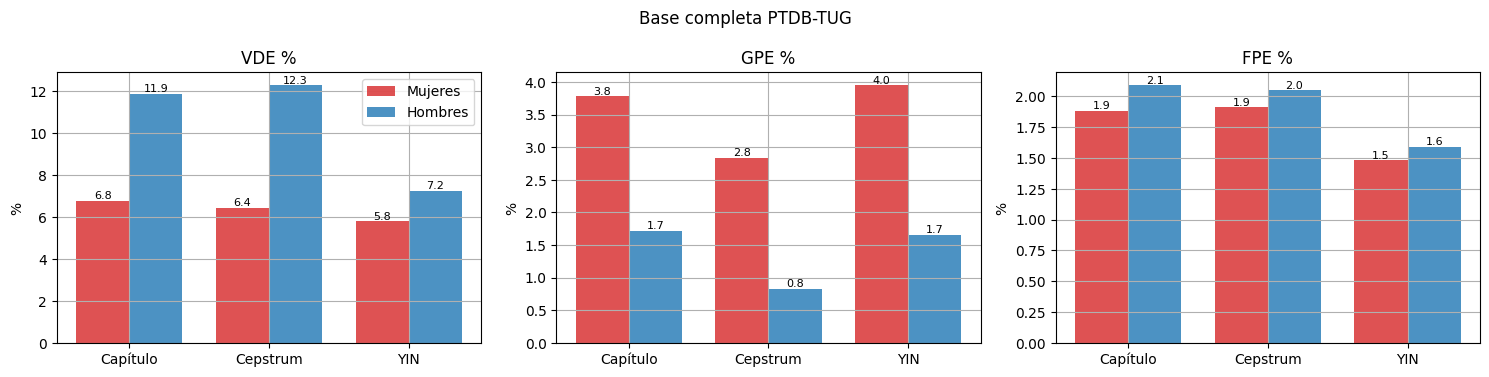

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
x = np.arange(len(METODOS)); ancho = 0.38
for ax, met in zip(axes, ["VDE %", "GPE %", "FPE %"]):
    for j, (grupo, color) in enumerate([("Mujeres", "tab:red"), ("Hombres", "tab:blue")]):
        vals = [tabla.loc[(m, grupo), met] for m in METODOS]
        barras = ax.bar(x + (j - 0.5) * ancho, vals, ancho, label=grupo, color=color, alpha=0.8)
        ax.bar_label(barras, fmt="%.1f", fontsize=8)
    ax.set_xticks(x, METODOS); ax.set_title(met); ax.set_ylabel("%")
axes[0].legend()
fig.suptitle("Base completa PTDB-TUG")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_metricas_por_sexo_base_completa.png", dpi=120, bbox_inches="tight"); plt.show()

## 4. Resultados por hablante

Las métricas acumuladas pueden esconder que un método funcione muy bien con algunos hablantes y mal con otros. Se
calculan VDE, GPE y FPE **para cada uno de los 20 hablantes** y se grafica su distribución (cada punto es un hablante).

Para ver si las diferencias entre métodos son consistentes se usa el **test de Wilcoxon de rangos con signo** (pareado:
se compara cada hablante consigo mismo con dos métodos). Un p-valor < 0,05 indica que la diferencia se repite en la
mayoría de los hablantes y no se debe al azar.

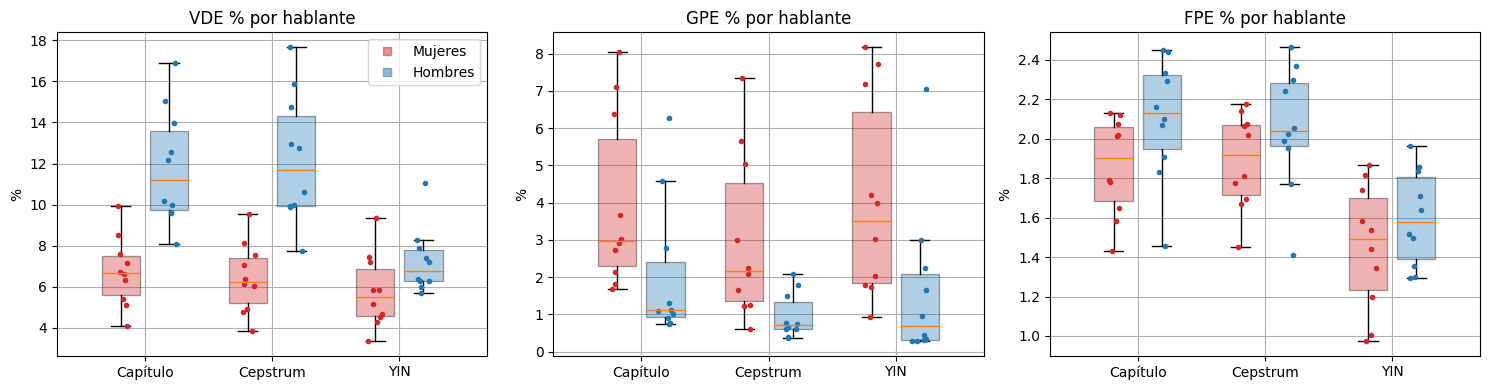

VDE %                   GPE %                  FPE %              
Método   Capítulo Cepstrum   YIN Capítulo Cepstrum  YIN Capítulo Cepstrum  YIN
hablante                                                                      
F01           6.6      6.1   5.9      2.1      1.3  4.2      2.1      2.1  1.7
F02           6.3      6.0   7.2      1.8      0.6  0.9      1.7      1.7  1.3
F03           5.4      4.9   4.7      2.9      2.1  1.7      1.6      1.7  1.2
F04           9.9      9.5   9.4      2.7      2.2  4.0      2.1      2.2  1.9
F05           6.7      6.4   5.1      3.7      3.0  3.0      2.0      2.0  1.6
F06           7.6      7.5   4.3      6.4      5.0  8.2      1.8      1.8  1.4
F07           4.1      3.8   3.4      1.7      1.2  2.0      1.4      1.5  1.0
F08           8.5      8.1   7.5      8.0      7.3  7.7      2.0      2.1  1.8
F09           5.1      4.8   4.5      3.0      1.7  1.8      2.1      2.1  1.5
F10           7.2      7.0   5.8      7.1      5.7  7.2      1.8      1.8  1.0
M01          12.5     12.9   6.3      4.6      1.8  7.1      2.1      2.0  1.7
M02          16.9     17.7  11.1      2.8      1.5  0.3      2.3      2.3  1.9
M03          15.0     15.9   7.9      0.7      0.4  0.3      1.9      2.0  1.3
M04          10.2     10.6   5.7      1.3      0.6  0.4      1.8      1.8  1.3
M05          10.0      9.9   8.3      1.1      0.8  3.0      2.4      2.4  2.0
M06          14.0     14.8   6.0      1.0      0.4  0.3      1.5      1.4  1.4
M07           8.1      7.8   6.4      0.8      0.6  2.2      2.1      2.0  1.8
M08          12.2     12.7   7.2      6.3      2.1  0.3      2.4      2.5  1.6
M09           9.6      9.9   6.3      1.1      0.8  1.0      2.2      2.1  1.5
M10           9.7     10.0   7.4      0.9      0.7  1.6      2.3      2.2  1.5

In [7]:
por_hablante = []
for h in HABLANTES:
    df = res[res["hablante"] == h]
    for m in METODOS:
        por_hablante.append({"hablante": h, "sexo": df["sexo"].iloc[0], "Método": m,
                             "F0 media ref [Hz]": float(np.concatenate(list(df["ref"]))[np.concatenate(list(df["ref"])) > 0].mean()),
                             **metricas_grupo(df, m)})
ph = pd.DataFrame(por_hablante)
ph.to_csv(RESULTS / "03_metricas_por_hablante.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, met in zip(axes, ["VDE %", "GPE %", "FPE %"]):
    for j, (grupo, color) in enumerate([("Mujeres", "tab:red"), ("Hombres", "tab:blue")]):
        datos = [ph[(ph["Método"] == m) & (ph["sexo"] == grupo)][met].values for m in METODOS]
        pos = np.arange(len(METODOS)) + (j - 0.5) * 0.38
        bp = ax.boxplot(datos, positions=pos, widths=0.3, patch_artist=True, showfliers=False)
        for caja in bp["boxes"]:
            caja.set_facecolor(color); caja.set_alpha(0.35)
        for p_, d_ in zip(pos, datos):
            ax.plot(np.full(len(d_), p_) + np.random.uniform(-0.06, 0.06, len(d_)), d_, "o", color=color, ms=3)
    ax.set_xticks(np.arange(len(METODOS)), METODOS); ax.set_title(f"{met} por hablante"); ax.set_ylabel("%")
axes[0].plot([], [], "s", color="tab:red", alpha=0.5, label="Mujeres")
axes[0].plot([], [], "s", color="tab:blue", alpha=0.5, label="Hombres"); axes[0].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "03_metricas_por_hablante.png", dpi=120, bbox_inches="tight"); plt.show()

pivot = ph.pivot(index="hablante", columns="Método", values=["VDE %", "GPE %", "FPE %"]).round(1)
pivot

In [8]:
pruebas = []
for met in ["VDE %", "GPE %", "FPE %"]:
    for grupo in ["Mujeres", "Hombres", "Todos"]:
        sub = ph if grupo == "Todos" else ph[ph["sexo"] == grupo]
        tabla_m = sub.pivot(index="hablante", columns="Método", values=met)
        for a_, b_ in [("YIN", "Capítulo"), ("Cepstrum", "Capítulo"), ("YIN", "Cepstrum")]:
            dif = tabla_m[a_] - tabla_m[b_]
            p = wilcoxon(tabla_m[a_], tabla_m[b_]).pvalue
            pruebas.append({"Métrica": met, "Grupo": grupo, "Comparación": f"{a_} vs {b_}",
                            "mediana de la diferencia": round(float(np.median(dif)), 2),
                            "hablantes donde el 1º tiene menos error": f"{int(np.sum(dif < 0))}/{len(dif)}",
                            "p-valor": float(f"{p:.2g}")})
pruebas = pd.DataFrame(pruebas)
pruebas.to_csv(RESULTS / "03_wilcoxon_por_hablante.csv", index=False)
pruebas

,Métrica,Grupo,Comparación,mediana de la diferencia,hablantes donde el 1º tiene menos error,p-valor
0,VDE %,Mujeres,YIN vs Capítulo,-0.76,9/10,0.027000
1,VDE %,Mujeres,Cepstrum vs Capítulo,-0.34,10/10,0.002000
2,VDE %,Mujeres,YIN vs Cepstrum,-0.36,9/10,0.037000
3,VDE %,Hombres,YIN vs Capítulo,-4.75,10/10,0.002000
4,VDE %,Hombres,Cepstrum vs Capítulo,0.41,2/10,0.020000
5,VDE %,Hombres,YIN vs Cepstrum,-5.24,10/10,0.002000
6,VDE %,Todos,YIN vs Capítulo,-1.72,19/20,0.000027
7,VDE %,Todos,Cepstrum vs Capítulo,-0.13,12/20,0.780000
8,VDE %,Todos,YIN vs Cepstrum,-1.49,19/20,0.000036
9,GPE %,Mujeres,YIN vs Capítulo,-0.12,5/10,0.770000


## 5. ¿El error depende de la F0 del hablante?

Cada punto es un hablante: en el eje x su F0 media (según el laringógrafo) y en el eje y el error de cada método. Sirve
para ver si los errores se concentran en voces más graves o más agudas, más allá de la división mujer/hombre.

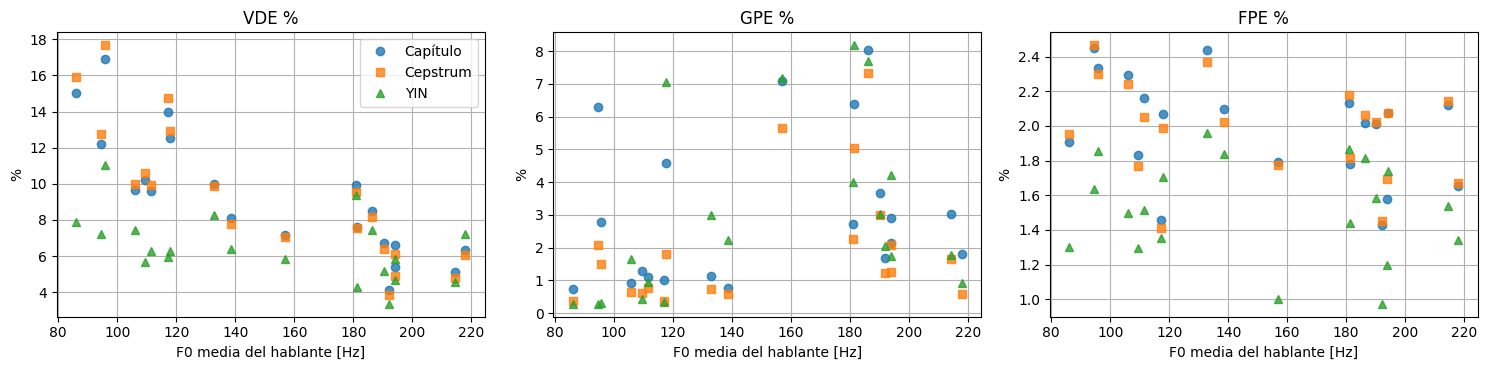

Correlación de Spearman entre F0 media del hablante y cada error:
  Capítulo   VDE: -0.88   GPE: +0.34   FPE: -0.43
  Cepstrum   VDE: -0.91   GPE: +0.32   FPE: -0.30
  YIN        VDE: -0.52   GPE: +0.53   FPE: -0.10


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
for ax, met in zip(axes, ["VDE %", "GPE %", "FPE %"]):
    for m, mk in zip(METODOS, ["o", "s", "^"]):
        sub = ph[ph["Método"] == m]
        ax.plot(sub["F0 media ref [Hz]"], sub[met], mk, label=m, alpha=0.8)
    ax.set_xlabel("F0 media del hablante [Hz]"); ax.set_ylabel("%"); ax.set_title(met)
axes[0].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "03_error_vs_f0_hablante.png", dpi=120, bbox_inches="tight"); plt.show()

print("Correlación de Spearman entre F0 media del hablante y cada error:")
for m in METODOS:
    sub = ph[ph["Método"] == m]
    print(f"  {m:9}  VDE: {sub['F0 media ref [Hz]'].corr(sub['VDE %'], method='spearman'):+.2f}   "
          f"GPE: {sub['F0 media ref [Hz]'].corr(sub['GPE %'], method='spearman'):+.2f}   "
          f"FPE: {sub['F0 media ref [Hz]'].corr(sub['FPE %'], method='spearman'):+.2f}")

## 6. Errores de octava en la base completa

Igual que en el notebook 02: entre los errores gruesos, qué porcentaje es de **octava arriba** ($F0_{est} \approx 2\,F0_{ref}$,
el error que advierte el capítulo para voces femeninas) y cuál de **octava abajo** ($\approx F0_{ref}/2$).

In [10]:
filas = []
for m in METODOS:
    for grupo in ["Mujeres", "Hombres"]:
        q_total = []
        for e, r in zip(res[res["sexo"] == grupo][m], res[res["sexo"] == grupo]["ref"]):
            n = min(len(e), len(r)); e, r = e[:n], r[:n]
            ambas = (e > 0) & (r > 0)
            q = e[ambas] / r[ambas]
            q_total.append(q[np.abs(q - 1) > 0.2])
        q = np.concatenate(q_total)
        filas.append({"Método": m, "Grupo": grupo, "errores gruesos": len(q),
                      "octava arriba (~2x) %": round(100 * np.mean(np.abs(q - 2) < 0.2), 1),
                      "octava abajo (~0.5x) %": round(100 * np.mean(np.abs(q - 0.5) < 0.1), 1),
                      "otros %": round(100 * np.mean((np.abs(q - 2) >= 0.2) & (np.abs(q - 0.5) >= 0.1)), 1)})
octavas = pd.DataFrame(filas).set_index(["Método", "Grupo"])
octavas

errores gruesos  octava arriba (~2x) %  \
Método   Grupo                                             
Capítulo Mujeres            12573                   41.9   
         Hombres             3688                   41.5   
Cepstrum Mujeres             9507                   50.9   
         Hombres             1690                   33.0   
YIN      Mujeres            14442                   70.8   
         Hombres             4906                   81.2   

                  octava abajo (~0.5x) %  otros %  
Método   Grupo                                     
Capítulo Mujeres                    44.6     13.5  
         Hombres                     2.2     56.3  
Cepstrum Mujeres                    33.5     15.7  
         Hombres                     3.9     63.1  
YIN      Mujeres                    19.3      9.9  
         Hombres                     8.1     10.6

## 7. Escuchar cualquier grabación con el decodificador LPC10

Elegir cualquier hablante y frase de la base (por ejemplo `("M05", "sx100")`) para escuchar la voz resintetizada con cada
estimador y con la F0 del laringógrafo. Es el mismo decodificador `lpc10` de los notebooks 01 y 02.

In [11]:
ESCUCHAR = [("F05", "sa2"), ("M05", "sa2")]

def lpc10(speech_HF, f0_tramas, fs=FS):
    n_tramas = min(len(f0_tramas), (len(speech_HF) - L_TRAMA) // SALTO + 1)
    z = np.zeros(P); offset = 0; synt_speech = []
    for i in range(n_tramas):
        input_frame = speech_HF[i * SALTO:i * SALTO + L_TRAMA]
        ai, sigma2 = lpc(input_frame * np.hamming(L_TRAMA), P)
        sigma = np.sqrt(sigma2)
        N0 = int(round(fs / f0_tramas[i])) if f0_tramas[i] > 0 else 0
        if N0 != 0:
            if offset >= SALTO:
                excitation = np.zeros(SALTO); offset -= SALTO
            else:
                excitation = list(np.zeros(offset))
                for _ in range((SALTO - offset) // N0):
                    excitation += [1.0] + [0.0] * (N0 - 1)
                flush = SALTO - len(excitation)
                if flush != 0:
                    excitation += [1.0] + [0.0] * (flush - 1); offset = N0 - flush
                else:
                    offset = 0
                excitation = np.array(excitation)
            gain = sigma / np.sqrt(1 / N0)
        else:
            excitation = np.random.randn(SALTO); gain = sigma; offset = 0
        synt_frame, z = lfilter([gain], ai, excitation, zi=z)
        synt_speech.append(synt_frame)
    return np.concatenate(synt_speech)

for h, frase in ESCUCHAR:
    fila = res[(res["hablante"] == h) & (res["frase"] == frase)]
    if fila.empty:
        print(f"{h} {frase} no está en la evaluación (falta en la base o es de calibración)"); continue
    fila = fila.iloc[0]
    speech, _ = cargar(h, frase)
    print(f"===== {h} {frase} =====")
    print("Original:"); display(Audio(speech, rate=FS))
    for nombre, f0 in [*[(m, fila[m]) for m in METODOS], ("Laringógrafo", fila["ref"])]:
        np.random.seed(0)
        print(f"LPC10 con F0 de {nombre}:"); display(Audio(lpc10(speech, f0), rate=FS))

===== F05 sa2 =====
Original:


LPC10 con F0 de Capítulo:


LPC10 con F0 de Cepstrum:


LPC10 con F0 de YIN:


LPC10 con F0 de Laringógrafo:


===== M05 sa2 =====
Original:


LPC10 con F0 de Capítulo:


LPC10 con F0 de Cepstrum:


LPC10 con F0 de YIN:


LPC10 con F0 de Laringógrafo:


### 7.1 Biblioteca de audios para comparar

Se generan y guardan los audios de un conjunto fijo de grabaciones para poder escuchar cualquiera sin correr nada:

- frases `sa1` y `sa2` de **los 20 hablantes** (todos leen esas dos frases: es la mejor comparación entre mujeres y
  hombres), y
- las **2 primeras frases `sx` de cada par** mujer/hombre (misma frase leída por una mujer y un hombre).

En total 80 grabaciones × 5 versiones = **400 audios**. Por cada grabación:

| Archivo | Contenido |
|---|---|
| `1_original.wav` | voz a 8 kHz tal como entra al codificador (después del remuestreo y el pasa-altos) |
| `2_capitulo.wav` | LPC10 con la F0 del estimador del capítulo |
| `3_cepstrum.wav` | LPC10 con la F0 del cepstrum |
| `4_yin.wav` | LPC10 con la F0 de YIN |
| `5_laringografo.wav` | LPC10 con la F0 del laringógrafo (pitch perfecto: la mejor calidad posible con LPC10) |

Organización: `results/audio/03_base_completa/<frase>/<hablante>/`. Para comparar métodos se escuchan los 5 archivos
de una carpeta; para comparar mujeres y hombres, la misma frase en dos carpetas de hablante.

- En las cuatro versiones LPC10 el ruido de las tramas sordas es **el mismo** (semilla fija), así que lo único que cambia
  entre ellas es la F0 y la decisión sonoro/sordo.
- Cada archivo se normaliza a su pico para que todos suenen a un volumen parecido.
- `indice.xlsx` (Excel) tiene una fila por grabación con el texto, la F0 media y el VDE, GPE y FPE de cada método **en esa
  grabación**: sirve para elegir qué escuchar (por ejemplo, la grabación donde un método se equivoca más).
- Si los audios de una grabación ya existen, no se vuelven a generar. Los `.wav` no se suben a GitHub.

In [12]:
AUDIO_LIB = AUDIO_DIR / "03_base_completa"

# Texto de cada frase (lista oficial de frases TIMIT de la documentación de PTDB-TUG)
TEXTOS = {
    "sa1": "She had your dark suit in greasy wash water all year.",
    "sa2": "Don't ask me to carry an oily rag like that.",
    "sx3": "This was easy for us.",
    "sx4": "Jane may earn more money by working hard.",
    "sx48": "Grandmother outgrew her upbringing in petticoats.",
    "sx49": "At twilight on the twelfth day we'll have Chablis.",
    "sx93": "Cut a small corner off each edge.",
    "sx94": "Youngsters love common candy as treats.",
    "sx138": "The clumsy customer spilled some expensive perfume.",
    "sx139": "The bungalow was pleasantly situated near the shore.",
    "sx183": "Why else would Danny allow others to go?",
    "sx184": "The cat's meow always hurts my ears.",
    "sx228": "The viewpoint overlooked the ocean.",
    "sx229": "Are you looking for employment?",
    "sx273": "The angry boy answered but didn't look up.",
    "sx274": "Cliff was soothed by the luxurious massage.",
    "sx318": "Please dig my potatoes up before frost.",
    "sx319": "A big goat idly ambled through the farmyard.",
    "sx363": "The cow wandered from the farmland and became lost.",
    "sx364": "Each untimely income loss coincided with the breakdown of a heating system part.",
    "sx408": "I'd ride the subway, but I haven't enough change.",
    "sx409": "Eating spinach nightly increases strength miraculously.",
}

# Conjunto: sa1 y sa2 de los 20 hablantes + 2 primeras frases sx de cada par F/M
biblioteca = []
for frase in ["sa1", "sa2"]:
    biblioteca += [(h, frase) for h in HABLANTES]
for k in range(1, 11):
    f, m = f"F{k:02d}", f"M{k:02d}"
    sx_par = sorted({s for s in res[res["hablante"] == f]["frase"] if s.startswith("sx")}
                    & {s for s in res[res["hablante"] == m]["frase"] if s.startswith("sx")}, key=clave)[:2]
    for frase in sx_par:
        biblioteca += [(f, frase), (m, frase)]

VERSIONES = [("2_capitulo", "Capítulo"), ("3_cepstrum", "Cepstrum"), ("4_yin", "YIN"), ("5_laringografo", "ref")]

def guardar_excel(df, ruta_xlsx):
    # Excel con encabezado fijo, filtros y ancho de columnas ajustado al contenido
    with pd.ExcelWriter(ruta_xlsx, engine="openpyxl") as w:
        df.to_excel(w, index=False, sheet_name="indice")
        hoja = w.sheets["indice"]
        hoja.freeze_panes = "A2"
        hoja.auto_filter.ref = hoja.dimensions
        for col in hoja.columns:
            largo = max(len(str(c.value)) for c in col if c.value is not None)
            hoja.column_dimensions[col[0].column_letter].width = min(largo + 2, 60)

def guardar_wav(ruta_wav, x):
    ruta_wav.parent.mkdir(parents=True, exist_ok=True)
    wavfile.write(ruta_wav, FS, (0.9 * x / np.max(np.abs(x)) * 32767).astype(np.int16))

filas, generadas, t0 = [], 0, time.time()
for h, frase in biblioteca:
    fila = res[(res["hablante"] == h) & (res["frase"] == frase)].iloc[0]
    carpeta = AUDIO_LIB / frase / h
    archivos = [carpeta / "1_original.wav"] + [carpeta / f"{n}.wav" for n, _ in VERSIONES]
    if not all(a.exists() for a in archivos):
        speech, _ = cargar(h, frase)
        guardar_wav(carpeta / "1_original.wav", speech)
        for nombre, col in VERSIONES:
            np.random.seed(0)                       # mismo ruido sordo en las cuatro versiones
            guardar_wav(carpeta / f"{nombre}.wav", lpc10(speech, fila[col]))
        generadas += 1
    ref = fila["ref"]
    info = {"frase": frase, "hablante": h, "sexo": fila["sexo"], "texto": TEXTOS.get(frase, ""),
            "carpeta": f"{frase}/{h}", "F0 media ref [Hz]": round(float(ref[ref > 0].mean()), 1)}
    for m in METODOS:
        r = acumular([(fila[m], ref)])
        info[f"VDE {m} %"] = round(r["VDE %"], 1)
        info[f"GPE {m} %"] = round(r["GPE %"], 1)
        info[f"FPE {m} %"] = round(r["FPE %"], 1)
    filas.append(info)

indice = pd.DataFrame(filas)
guardar_excel(indice, AUDIO_LIB / "indice.xlsx")
print(f"{len(biblioteca)} grabaciones ({len(biblioteca) * 5} audios) en {AUDIO_LIB.resolve()}")
print(f"generadas ahora: {generadas} · ya existían: {len(biblioteca) - generadas} · {time.time() - t0:.0f} s")
indice[["frase", "hablante", "texto", "F0 media ref [Hz]", "VDE Capítulo %", "VDE YIN %", "GPE Capítulo %", "GPE YIN %"]].head(10)

80 grabaciones (400 audios) en C:\Users\VICTUS\Documents\2026\SyS\TPI\tpi-voz\results\audio\03_base_completa
generadas ahora: 80 · ya existían: 0 · 35 s


,frase,hablante,texto,F0 media ref [Hz],VDE Capítulo %,VDE YIN %,GPE Capítulo %,GPE YIN %
0,sa1,F01,She had your dark suit in greasy wash water al...,194.6,8.4,6.2,0.0,1.6
1,sa1,F02,She had your dark suit in greasy wash water al...,200.2,4.0,4.1,0.6,1.1
2,sa1,F03,She had your dark suit in greasy wash water al...,206.9,5.5,3.3,1.1,0.5
3,sa1,F04,She had your dark suit in greasy wash water al...,191.8,4.6,3.9,0.0,5.5
4,sa1,F05,She had your dark suit in greasy wash water al...,204.2,8.1,9.7,6.3,3.9
5,sa1,F06,She had your dark suit in greasy wash water al...,161.4,11.2,5.4,4.5,15.5
6,sa1,F07,She had your dark suit in greasy wash water al...,197.1,3.6,2.6,1.5,0.0
7,sa1,F08,She had your dark suit in greasy wash water al...,200.2,8.0,5.5,10.9,9.6
8,sa1,F09,She had your dark suit in greasy wash water al...,208.4,5.5,3.8,1.4,0.0
9,sa1,F10,She had your dark suit in greasy wash water al...,146.1,9.5,5.2,3.0,6.0


In [13]:
# Grabaciones de la biblioteca donde cada método comete más errores gruesos (para escuchar casos difíciles)
for m in METODOS:
    peor = indice.sort_values(f"GPE {m} %", ascending=False).iloc[0]
    print(f"{m:9}: más GPE en {peor['carpeta']} ({peor[f'GPE {m} %']} %)  —  \"{peor['texto']}\"")

Capítulo : más GPE en sx318/F08 (15.2 %)  —  "Please dig my potatoes up before frost."
Cepstrum : más GPE en sx318/F08 (16.4 %)  —  "Please dig my potatoes up before frost."
YIN      : más GPE en sx318/F08 (17.3 %)  —  "Please dig my potatoes up before frost."


## 8. Conclusiones

### Resumen de resultados (4678 grabaciones, ≈ 3,4 millones de tramas)

| Método | VDE mujeres / hombres | GPE mujeres / hombres | FPE mujeres / hombres |
|---|---|---|---|
| Capítulo | 6,8 / 11,9 % | 3,8 / 1,7 % | 1,9 / 2,1 % |
| Cepstrum | 6,4 / 12,3 % | **2,8 / 0,8 %** | 1,9 / 2,1 % |
| YIN | **5,8 / 7,2 %** | 4,0 / 1,7 % | **1,5 / 1,6 %** |

**Consistencia con el notebook 02**
El ranking se mantiene: YIN sigue siendo el mejor en la decisión sonoro/sordo (VDE) y en el error fino (FPE), cepstrum el que menos errores
gruesos comete (GPE) y el método del capítulo no es el mejor en ninguna métrica. Con la base completa todos los errores
suben entre 0,5 y 1 punto respecto de las 200 grabaciones del notebook 02, pero el orden entre métodos no cambia.

**Consistencia entre hablantes**
Las diferencias principales se repiten en casi todos los hablantes (test de Wilcoxon sobre los 20 hablantes,
sección 4):

- YIN tiene menor VDE que el capítulo en **19 de 20** hablantes y menor FPE en **20 de 20** (p < 0,001).
- Cepstrum tiene menor GPE que el capítulo en **20 de 20** hablantes (p < 0,001).
- Otras diferencias no son consistentes: en GPE, YIN y el capítulo están empatados (11 de 20, p = 0,99), y en VDE
  cepstrum y el capítulo también (12 de 20, p = 0,78). En hombres, cepstrum incluso decide sonoro/sordo algo peor que el
  capítulo (mejor solo en 2 de 10).

**Hablantes con más errores**
Algunos hablantes concentran más errores, y suelen ser los mismos para los tres métodos, lo que indica que la dificultad está en la voz y no en un método:

- **Errores gruesos altos en F06, F08 y F10** (GPE de 5 a 8 % con los tres métodos). Son justamente mujeres con tramas
  muy graves (p5 de la F0 cercano a 80–100 Hz), probablemente voz *creaky* al final de las frases.
- **Error sonoro/sordo alto en M02, M03 y M06** con el capítulo y cepstrum (VDE de 14 a 18 %). YIN lo reduce a 6–11 %.
- Casos puntuales: M01 con YIN (GPE 7,1 %) y M08 con el capítulo (GPE 6,3 %).

**Relación entre el error y la F0 del hablante**
Los errores dependen de la F0 media de cada hablante (correlación de Spearman, sección 5):

- **VDE:** cuanto más grave la voz, más errores de decisión sonoro/sordo. La relación es muy fuerte en el capítulo
  (−0,88) y en cepstrum (−0,91), y bastante más débil en YIN (−0,52). Una explicación posible de por qué YIN mejora tanto en
  hombres: con F0 baja, la trama de 30 ms contiene pocos períodos y el pico de autocorrelación o del cepstrum queda bajo el umbral,
  mientras que la función diferencia normalizada de YIN sigue marcando el período.
- **GPE:** la relación es al revés y más débil (+0,32 a +0,53): las voces más agudas tienen algo más de errores gruesos.
- **FPE:** casi no depende de la F0 en YIN (−0,10).

**Errores de octava**
El patrón del notebook 02 se confirma en parte (sección 6). El capítulo advierte que en voces femeninas el segundo armónico puede confundirse con F0 (octava
arriba). Con la base completa, en mujeres el método del capítulo reparte sus errores gruesos casi por igual entre octava
arriba (42 %) y octava abajo (45 %), así que la advertencia del capítulo se cumple pero no es el único error. YIN, en
cambio, falla casi siempre hacia arriba (71 % en mujeres y 81 % en hombres): cuando se equivoca, elige un sub-período.
En hombres, el capítulo y cepstrum tienen pocos errores de octava abajo y la mayoría de sus errores gruesos no son de
octava (56–63 %).

**Percepción de la voz resintetizada**
Las diferencias entre métodos no se escuchan de forma notoria. Las versiones decodificadas con los tres estimadores y con la F0 del laringógrafo suenan muy
parecidas, y en todas la frase se entiende correctamente. La impresión del grupo es que con YIN la entonación es
levemente mejor, lo que coincide con su menor FPE y VDE, pero la diferencia es sutil. Lo que domina el sonido es el
carácter robótico propio del LPC10 (excitación de pulsos perfectos o ruido), que es igual para los cuatro casos.

### Conclusión general

De los tres estimadores evaluados, **YIN es la mejor opción para el bloque de pitch y decisión sonoro/sordo del
LPC10**: comete menos errores de decisión sonoro/sordo, es el más preciso cuando acierta y es el menos sensible a lo grave
de la voz. Cepstrum es el más robusto frente a errores gruesos y el método del capítulo, el más simple, tiene su punto
débil en la decisión sonoro/sordo de voces graves. Aun así, con los tres la voz decodificada es inteligible y las
diferencias casi no se perciben, porque la calidad del LPC10 está limitada sobre todo por su modelo de excitación y no por
el estimador de pitch.

### Consideraciones sobre la base de datos al interpretar los resultados

- **Comparación controlada por sexo:** como cada par mujer/hombre leyó el mismo texto, las diferencias entre mujeres y
  hombres no se deben a las frases.
- **Más de tres cuartos de las tramas son sordas o silencio** (≈ 23 % de tramas sonoras, por el silencio del protocolo y
  por las consonantes sordas). Un estimador que dijera "sorda" siempre tendría un VDE de ≈ 23 %; los VDE de 6–12 % de este
  trabajo hay que leerlos contra esa base.
- **La referencia no es perfecta:** es la salida de otro estimador (RAPT) sobre el laringógrafo. Hay valores extremos
  (53 y 535 Hz) que probablemente son errores de la propia referencia. Como se acordó con el tutor, no se corrigen.
- **Algunas mujeres tienen tramas muy graves** (p5 cercano o menor a 100 Hz en F04, F06, F08 y F10). Puede deberse a voz
  "creaky" (vocal fry) al final de las frases o a errores de la referencia, y explica parte de los errores en esas
  hablantes.
- **Condiciones ideales:** estudio, micrófono pegado a la boca, habla leída y adultos jóvenes. Los resultados representan
  el mejor caso; en un celular real (ruido ambiente, micrófono más lejos, compresión) los errores serían mayores.
- **Sin anotación fonética:** la base no marca dónde está cada fonema; la única información temporal es la F0 cada 10 ms.
- **Mismos umbrales del notebook 02:** se calibraron con 40 grabaciones que no se usan acá; no se reajustaron con la base
  completa.